Команды для получения матрицы корреляции

In [ ]:
!pip install mrmr_selection
import pandas as pd
import seaborn as sns
from mrmr import mrmr_classif
from sklearn.preprocessing import LabelEncoder

Команды для построения модели

In [ ]:
!pip install optuna
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, f1_score, roc_curve, auc, ConfusionMatrixDisplay, roc_curve
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import OneHotEncoder
import optuna
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import ExtraTreesClassifier
import warnings
warnings.filterwarnings('ignore')

## Название модели/курсовой работы:

Предсказание пятилетней выживаемости по первичной опухоли с помощью текстурного анализа

### Описание датасета:
Датасет взят из базы данных HNSCC с сайта https://radiomics.uk/

In [ ]:
#Сайт работает при помощи VPN

### Загрузка датасета

In [ ]:
#В силу того, что исходный датасет содержал много лишних и нестандартизированных данных, то пришлось руками это всё дело чистить

Выводим labels из нашей общей таблицы

In [ ]:
df = pd.read_csv('../tools/HNSCC_merged.csv')
labels = df['label']
labels

,label
0,1
1,0
2,0
3,0
4,1
...,...
120,0
121,0
122,0
123,0


Выводим features, также из общей таблицы

In [ ]:
df = pd.read_csv('../tools/HNSCC_merged.csv')
data = df.iloc[:, :-5]
data

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,0.851051,0.680475,29.876659,43.905619,46.518813,54.037024,49.477268,56.071383,28211.666667,37.365919,...,0.010144,0.000494,0.182273,1013.341350,0.000329,0.042584,0.002157,12656.374571,0.052121,54.382958
1,0.665514,0.500588,43.043509,85.985899,97.508974,75.894664,89.822046,101.862653,126419.333333,57.224851,...,0.021098,0.000475,0.287067,2163.515122,0.000218,0.116768,0.000405,58790.156999,0.092128,15.751062
2,0.616316,0.505574,21.838750,43.195994,44.721360,44.721360,32.310989,46.690470,16010.333333,26.622361,...,0.059812,0.002011,0.092652,202.644212,0.000464,0.086239,0.003503,1141.658514,0.025437,17.275182
3,0.708820,0.594757,22.355978,37.588434,42.379240,44.721360,33.526109,45.825757,15139.333333,26.643416,...,0.118345,0.002679,0.134580,164.224999,0.001393,0.130696,0.002324,1589.093695,0.052017,14.710386
4,0.798183,0.553756,47.978726,86.642419,104.403065,73.539105,103.576059,106.695829,103905.333333,69.156486,...,0.049587,0.000575,0.074070,200.192487,0.000127,0.252114,0.000507,2998.663042,0.004147,8.328032
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,0.892248,0.642091,32.117772,50.020628,56.462377,59.363288,55.569776,61.741396,42484.333333,44.630809,...,3.488890,0.019106,0.251020,472.719609,0.002016,0.224924,0.000923,13328.573826,0.858100,6.558111
121,0.480346,0.365836,18.695157,51.102575,53.141321,52.801515,30.463092,57.271284,14650.666667,24.546899,...,0.464075,0.011581,0.340957,642.790266,0.002776,0.070162,0.002798,15476.909212,0.572131,13.029557
122,0.582105,0.407536,26.684675,65.478124,56.920998,66.603303,46.690470,69.799713,33099.000000,38.115148,...,1.622821,0.013190,0.309337,643.757455,0.002006,0.128204,0.001215,21478.357047,0.418453,12.971275
123,0.648126,0.399800,29.017481,72.579992,72.498276,44.271887,60.827625,75.206383,13989.333333,47.040979,...,0.028608,0.001130,0.161170,371.476274,0.000803,0.057228,0.003750,2711.311665,0.038681,18.259131


Клинические данные достаём из нашей таблицы

In [ ]:
clinical_data=pd.DataFrame(df)
clinical_data.reset_index(drop=True, inplace=True)
clinical_data.rename(columns={'Age':'age', 'Sex':'sex', 'Current Smoker':'current smoker', 'BMI start treat (kg/m2)':'bmi'}, inplace=True)
clin_data = clinical_data.iloc[:,-5:-1]
clin_data.reset_index(inplace=True, drop=True)

### Селекция признаков

Отбираем признаки с помощью mrmr

In [ ]:
selected_features_ks = mrmr_classif(X=data, y=labels, K=10, relevance='ks')

100%|██████████| 10/10 [00:00<00:00, 24.85it/s]


In [ ]:
selected_features_rf = mrmr_classif(X=data, y=labels, K=10, relevance='rf')

100%|██████████| 10/10 [00:00<00:00, 28.32it/s]


In [ ]:
selected_features_all = set(selected_features_ks + selected_features_rf)

Выбираем данные, соответствующие выбранным колонкам

In [ ]:
selected_data = data[sorted(selected_features_all)]

Строим матрицу корреляции и начинаем убирать коррелирующие признаки (критерий отбора: корреляция по Спирману < 0.7)

In [ ]:
corr_matrix = selected_data.corr(method='spearman').abs()

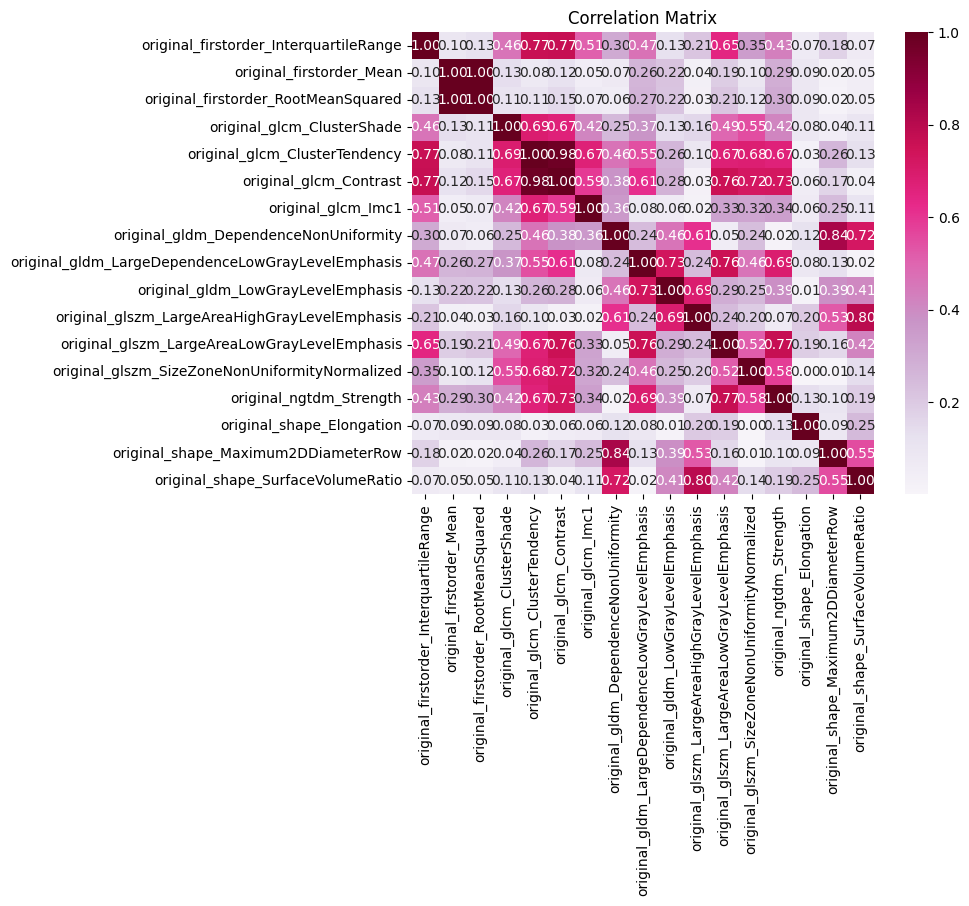

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='PuRd', fmt=".2f", square=True)
plt.title('Correlation Matrix')
plt.show()

In [ ]:
corr_matrix.loc[['original_glcm_Contrast','original_gldm_LowGrayLevelEmphasis','original_glszm_SizeZoneNonUniformityNormalized'], :].drop(['original_glcm_ClusterShade','original_gldm_LowGrayLevelEmphasis','original_glszm_SizeZoneNonUniformityNormalized'], axis=1).rank(method='min').sum(axis=1)

,0
original_glcm_Contrast,33.0
original_gldm_LowGrayLevelEmphasis,29.0
original_glszm_SizeZoneNonUniformityNormalized,22.0


In [ ]:
corr_matrix.loc[['original_shape_SurfaceVolumeRatio','original_glcm_ClusterShade','original_firstorder_Mean'], :].drop(['original_shape_SurfaceVolumeRatio','original_glcm_ClusterShade','original_firstorder_Mean'], axis=1).rank(method='min').sum(axis=1)

,0
original_shape_SurfaceVolumeRatio,28.0
original_glcm_ClusterShade,34.0
original_firstorder_Mean,22.0


Убираем признаки с наибольшим значением ранга

In [ ]:
selected_data.drop(['original_glcm_Contrast','original_gldm_LowGrayLevelEmphasis','original_glcm_ClusterShade','original_firstorder_Mean'], axis=1, inplace=True)

In [ ]:
corr_matrix_new = selected_data.corr(method='spearman').abs()

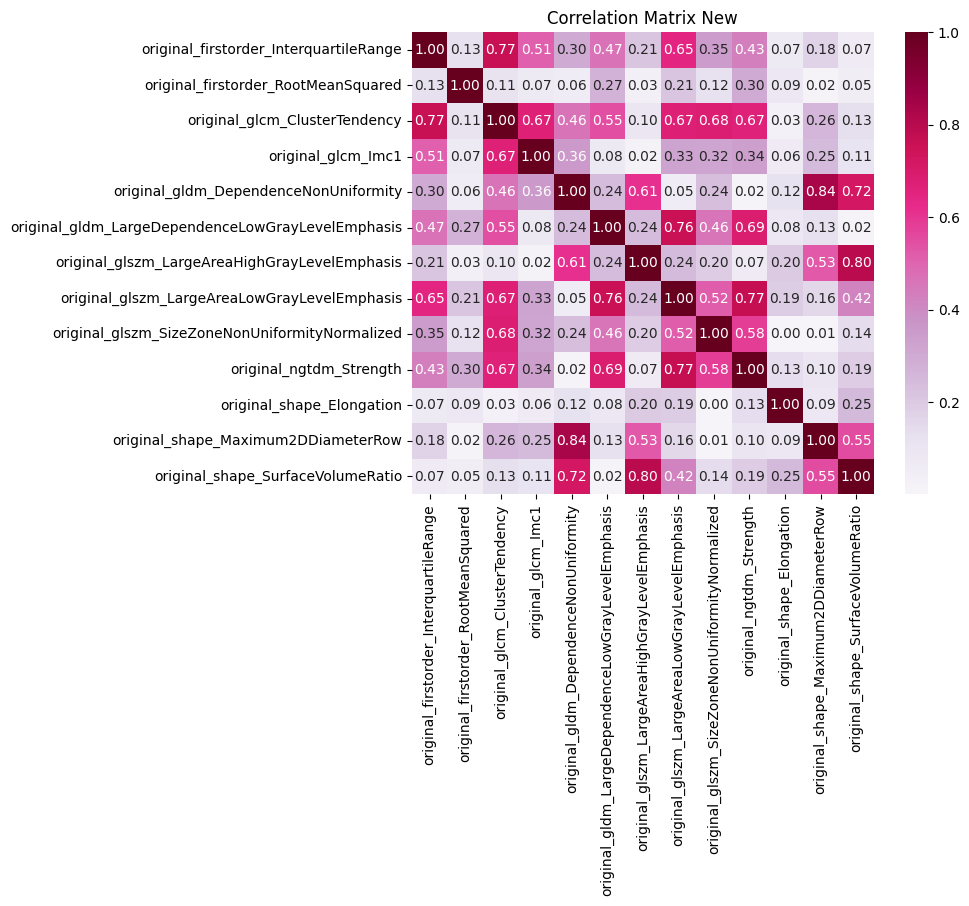

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix_new, annot=True, cmap='PuRd', fmt=".2f", square=True)
plt.title('Correlation Matrix New')
plt.show()

In [ ]:
(corr_matrix_new > 0.7).sum(axis=1) - 1

,0
original_firstorder_InterquartileRange,1
original_firstorder_RootMeanSquared,0
original_glcm_ClusterTendency,1
original_glcm_Imc1,0
original_gldm_DependenceNonUniformity,2
original_gldm_LargeDependenceLowGrayLevelEmphasis,1
original_glszm_LargeAreaHighGrayLevelEmphasis,1
original_glszm_LargeAreaLowGrayLevelEmphasis,2
original_glszm_SizeZoneNonUniformityNormalized,0
original_ngtdm_Strength,1


In [ ]:
selected_data.corr(method='spearman').abs().loc[selected_data.filter(like='glszm').columns, :].drop(selected_data.filter(like='glszm').columns, axis=1).rank(method='min').sum(axis=1)

,0
original_glszm_LargeAreaHighGrayLevelEmphasis,18.0
original_glszm_LargeAreaLowGrayLevelEmphasis,24.0
original_glszm_SizeZoneNonUniformityNormalized,18.0


In [ ]:
corr_matrix_new.loc[['original_gldm_DependenceNonUniformity','original_glcm_ClusterTendency'], :].drop(['original_gldm_DependenceNonUniformity','original_glcm_ClusterTendency'], axis=1).rank(method='min').sum(axis=1)

,0
original_gldm_DependenceNonUniformity,15.0
original_glcm_ClusterTendency,18.0


In [ ]:
selected_data.drop(['original_glszm_LargeAreaLowGrayLevelEmphasis','original_glcm_ClusterTendency'], axis=1, inplace=True)

In [ ]:
new_corr_matrix = selected_data.corr(method='spearman').abs()

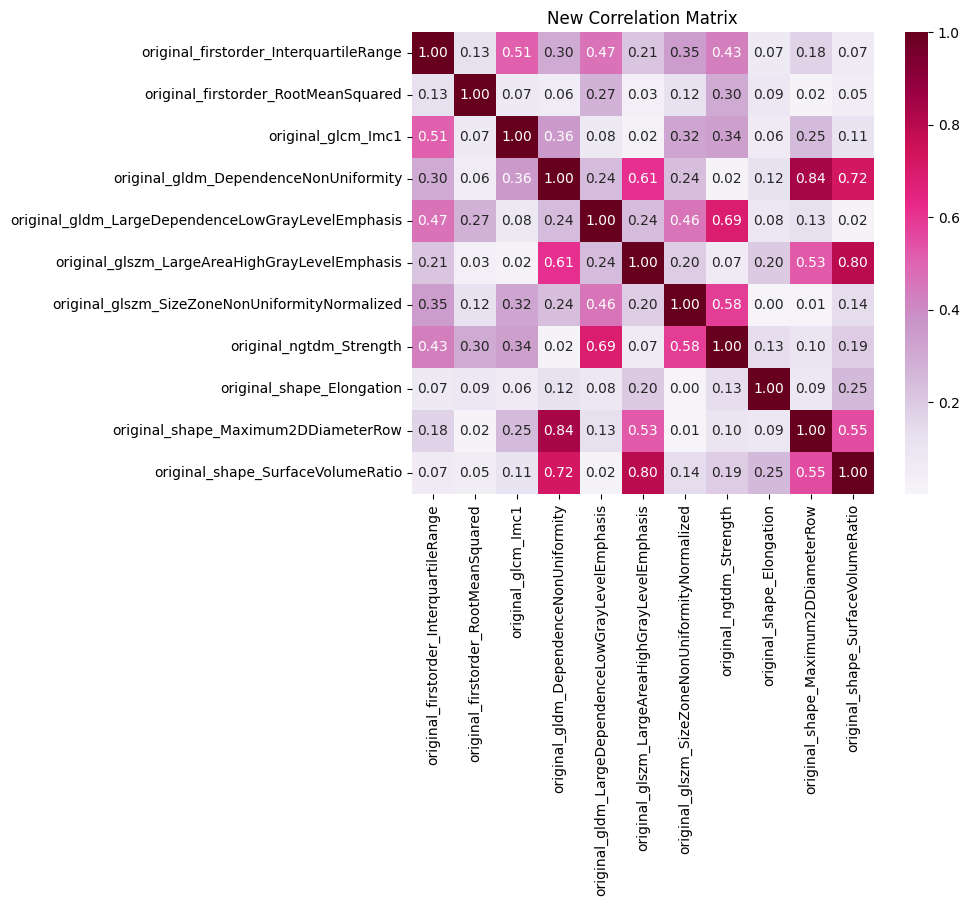

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(new_corr_matrix, annot=True, cmap='PuRd', fmt=".2f", square=True)
plt.title('New Correlation Matrix')
plt.show()

Полученный результат

In [ ]:
selected_data.columns

Index(['original_firstorder_InterquartileRange',
       'original_firstorder_RootMeanSquared', 'original_glcm_Imc1',
       'original_gldm_DependenceNonUniformity',
       'original_gldm_LargeDependenceLowGrayLevelEmphasis',
       'original_glszm_LargeAreaHighGrayLevelEmphasis',
       'original_glszm_SizeZoneNonUniformityNormalized',
       'original_ngtdm_Strength', 'original_shape_Elongation',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_SurfaceVolumeRatio'],
      dtype='object')

### Объединение данных

Объединяем при помощи concat

In [ ]:
union_data= pd.concat([selected_data,clin_data], axis=1)
union_data

,original_firstorder_InterquartileRange,original_firstorder_RootMeanSquared,original_glcm_Imc1,original_gldm_DependenceNonUniformity,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_glszm_LargeAreaHighGrayLevelEmphasis,original_glszm_SizeZoneNonUniformityNormalized,original_ngtdm_Strength,original_shape_Elongation,original_shape_Maximum2DDiameterRow,original_shape_SurfaceVolumeRatio,sex,age,current smoker,bmi
0,61.491348,2371.241395,-0.136014,305.037630,0.010144,1.001259e+07,0.474446,54.382958,0.851051,54.037024,0.271386,Female,54,0,19.618030
1,162.916595,2597.108272,-0.230197,1538.739059,0.021098,1.892700e+07,0.602889,15.751062,0.665514,75.894664,0.170175,Female,56,1,21.229496
2,31.369889,2124.463493,-0.134714,101.947577,0.059812,1.304401e+07,0.415868,17.275182,0.616316,44.721360,0.265112,Male,48,1,29.604848
3,21.486175,1721.356466,-0.160381,83.810246,0.118345,8.900673e+06,0.559071,14.710386,0.708820,44.721360,0.254875,Male,66,1,33.633332
4,34.481990,1987.361018,-0.146568,622.711286,0.049587,1.010781e+08,0.389658,8.328032,0.798183,73.539105,0.181235,Male,39,0,29.773557
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,1198.489814,1798.852641,-0.277513,448.059903,3.488890,2.418655e+06,0.582555,6.558111,0.892248,59.363288,0.217207,Male,76,0,29.480760
121,314.504072,1882.058068,-0.268629,265.932542,0.464075,3.337438e+05,0.550160,13.029557,0.480346,52.801515,0.292889,Male,63,0,39.545134
122,617.681228,1846.362234,-0.258859,458.232318,1.622821,1.656177e+06,0.663263,12.971275,0.582105,66.603303,0.282622,Male,66,1,24.653627
123,67.384824,2048.837752,-0.200170,122.166853,0.028608,1.852162e+06,0.416493,18.259131,0.648126,44.271887,0.382743,Male,59,1,30.420135


### Модель

In [ ]:
train_df, validate_df, train_labels, validate_labels = train_test_split(union_data, labels, stratify=labels, test_size=0.2, random_state=42)

In [ ]:
numeric_features = union_data.select_dtypes(include=['number']).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat_sex', OneHotEncoder(drop='first'), ['sex'])])
pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

train_encoded = pipeline.fit_transform(train_df)

test_encoded = pipeline.transform(validate_df)

In [ ]:
X_train, y_train = train_encoded.copy(), train_labels.copy()
X_test, y_test = test_encoded.copy(), validate_labels.copy()

In [ ]:
rfc = ExtraTreesClassifier(random_state=42,
                           n_estimators=13,
                           max_depth=2,
                           min_samples_split=2)
rfc.fit( X_train, y_train)
roc_auc_score(y_train, rfc.predict(X_train)), roc_auc_score(y_test, rfc.predict(X_test)), f1_score(y_train, rfc.predict(X_train)), f1_score(y_test, rfc.predict(X_test))

(0.7, 0.641025641025641, 0.7115384615384616, 0.64)

### Метрики

AUC: 0.641, difference: 0.059;  
F1: 0.640, difference: 0.072

Добавляем Confusion Matrix

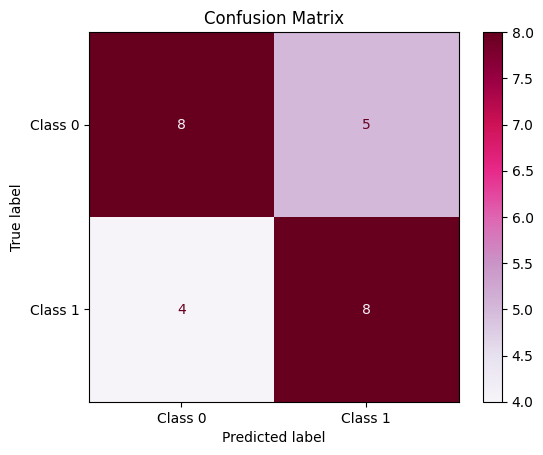

In [ ]:
cm = confusion_matrix(y_test, rfc.predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap=plt.cm.PuRd)
plt.title('Confusion Matrix')
plt.show()

Рассчитываем метрики

In [ ]:
TN, FP, FN, TP = cm.ravel()

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)
accuracy = (TP + TN) / (TP + TN + FP + FN)
ppv = TP / (TP + FP)
npv = TN / (TN + FN)
sensitivity, specificity, accuracy, ppv, npv

(0.6666666666666666,
 0.6153846153846154,
 0.64,
 0.6153846153846154,
 0.6666666666666666)

Вставляем ROC-curve

ROC AUC (train, predict): 0.7
ROC AUC (test, predict): 0.641025641025641


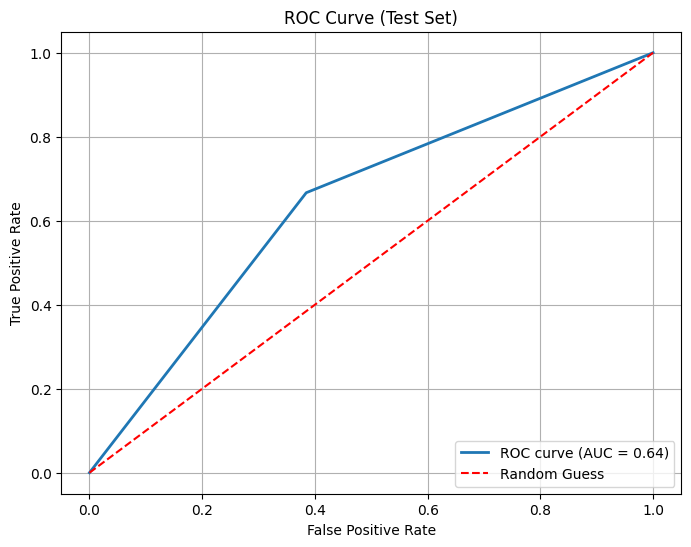

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, rfc.predict(X_test))
y_train_pred = rfc.predict(X_train)
y_test_pred  = rfc.predict(X_test)

roc_auc_train = roc_auc_score(y_train, y_train_pred)
roc_auc_test  = roc_auc_score(y_test, y_test_pred)

print("ROC AUC (train, predict):", roc_auc_train)
print("ROC AUC (test, predict):", roc_auc_test)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, lw=2, label=f'ROC curve (AUC = {roc_auc_test:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Test Set)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()